# 07 — Air Force Telegram posts as features
**Question:** do official Air Force threat posts (threat type, current oblast, direction — e.g. «БпЛА на Сумщині курсом на Полтавщину»)
improve the best alert-history model (v4, mean per-oblast PR-AUC 0.227 ± 0.021 at 30 min)?

**Data:** `data/telegram_raw.parquet` from `scrape_telegram.py` (channel `kpszsu`).
**Leakage rules** (`src/telegram.py`, tested in `tests/test_telegram.py`):
- a post is used only from the end of the 5-min bin it was **published** in;
- posts edited > 5 min after publication are dropped (edited text may contain later information);
- forwarded posts are dropped.

**Protocol:** identical to notebooks 05–06 (6 monthly walk-forward folds, 60-min embargo).

*Note:* Telegram API Terms §1.5 restrict using platform data to train ML models — this is an academic, non-commercial experiment; confirm with the supervisor before publishing.

In [1]:
import json, sys, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from pathlib import Path
from sklearn.metrics import average_precision_score, brier_score_loss

sys.path.insert(0, str(Path.cwd()))
from src.data import load_clean, sub_grid, raion_share_grid, regime_switch_date
from src.features import (build_features_v4, build_targets, compute_lift, HORIZONS, STEP,
                          OWN, CAL, SPATIAL, WAVE, ADJ_F, SUB, RAION, REGIME, nbr_cols)
from src.telegram import clean, tg_features, WEAPON_PATTERNS

sns.set_theme(style="whitegrid")
DATA_DIR = Path("data")
tg_raw = pd.read_parquet(DATA_DIR / "telegram_raw.parquet")
msgs = clean(tg_raw)
print(f"raw posts: {len(tg_raw)}, kept after edit/forward filter: {len(msgs)} ({len(msgs)/len(tg_raw):.0%})")
print("period:", msgs.date.min(), "→", msgs.date.max())

raw posts: 57950, kept after edit/forward filter: 52462 (91%)
period: 2025-01-25 02:01:46+02:00 → 2026-10-12 20:26:14+03:00


## 1. Sanity check: is this the official Air Force channel, and what does it post?

In [2]:
for t in msgs.sample(12, random_state=0).text:
    print("•", t[:200].replace("\n", " "))

• 🏍 Реактивний БпЛА на сході Київщини, курс на захід. 🏍 Реактивний БпЛА на півночі від Черкас, курс на захід
• Ракета на Харків
• 🛵 Харківщина: БпЛА в напрямку Дергачів - північного заходу.
• 🛵 БпЛА ➡️ курсом на Запоріжжя.
• ⚠Увага! ☄️ Загроза застосування балістичного озброєння  зі сходу!
• 🛵  Чернігівщина: БпЛА повз Бахмач курсом на захід.
• ⚡️ ЗБИТО/ПОДАВЛЕНО 132 ЦІЛІ ➖➖➖➖➖➖➖➖➖➖ У ніч на 16 липня (з 18:00 15 липня) противник атакував 8 балістичними ракетами Іскандер-М/С-400 із Брянської області, рф, 4 крилатими ракетами Х-22/32 з акватор
• 💣 КАБи на Дніпропетровську, Донецьку області!
• 🚀Пуски КАБ на Донеччину.
• 🛵 БпЛА повз Пирятин (Полтавщина), курс західний (Київщина).
• 🛵 Реактивний БпЛА на півдні Сумщини - курсом на Боромлю, Лебедин.
• 🏍 Реактивний БпЛА на Зміїв на Харківщині з півдня


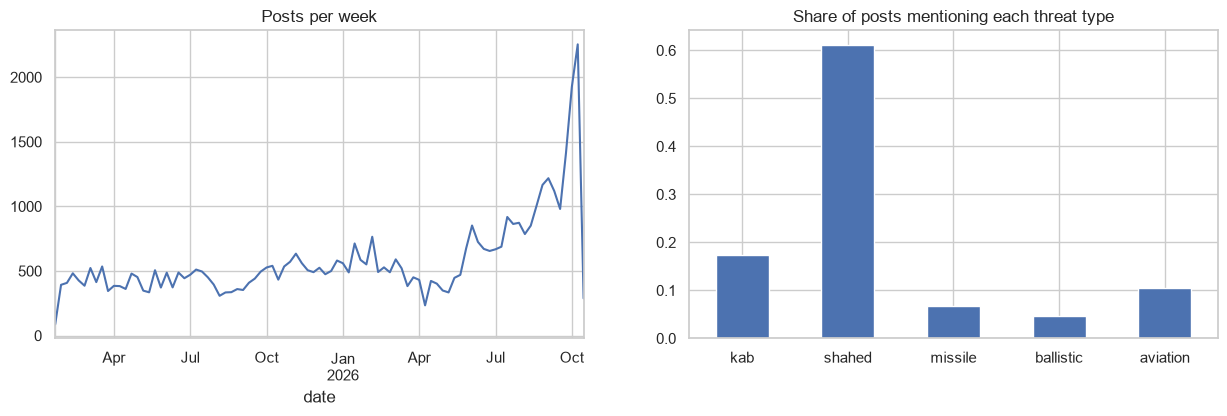

posts mentioning ≥1 oblast: 0.785 | with a direction phrase: 0.389


oblasts
Sumska oblast              8430
Kharkivska oblast          7610
Dnipropetrovska oblast     7254
Chernihivska oblast        6083
Donetska oblast            4317
Kyivska oblast             4042
Poltavska oblast           3895
Zaporizka oblast           3363
Mykolaivska oblast         2858
Kyiv City                  2008
Odeska oblast              1890
Zhytomyrska oblast         1498
Khersonska oblast          1488
Kirovohradska oblast       1151
Cherkaska oblast            550
Khmelnytska oblast          505
Rivnenska oblast            417
Vinnytska oblast            360
Volynska oblast             218
Ternopilska oblast          192
Lvivska oblast              111
Ivano-Frankivska oblast      34
Chernivetska oblast          14
Zakarpatska oblast            3
Name: count, dtype: int64

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
msgs.set_index("date").resample("W").size().plot(ax=ax[0], title="Posts per week")
pd.Series({w: msgs.weapons.map(lambda x: w in x).mean() for w in WEAPON_PATTERNS}).plot.bar(ax=ax[1], rot=0,
          title="Share of posts mentioning each threat type")
plt.show()
print("posts mentioning ≥1 oblast:", round(msgs.oblasts.map(len).gt(0).mean(), 3),
      "| with a direction phrase:", round(msgs.direction.mean(), 3))
msgs.explode("oblasts").oblasts.value_counts().head(24)

## 2. Lead time: how early do posts mention an oblast before its alert starts?
For every alert start, look back 3 h for the latest post that mentions that oblast.

In [4]:
state_all  = pd.read_parquet(DATA_DIR / "state_5min.parquet")
starts_all = pd.read_parquet(DATA_DIR / "starts_5min.parquet")
ep = pd.read_parquet(DATA_DIR / "episodes.parquet")
ep = ep[(ep.start >= msgs.date.min()) & (ep.start <= msgs.date.max())]

men = msgs.explode("oblasts").dropna(subset=["oblasts"])[["date", "oblasts"]].rename(columns={"oblasts": "oblast"})
rows = []
for o, g in ep.groupby("oblast"):
    m = men[men.oblast == o].sort_values("date")
    if m.empty: continue
    j = pd.merge_asof(g.sort_values("start")[["start"]], m[["date"]], left_on="start", right_on="date",
                      direction="backward", tolerance=pd.Timedelta("3h"))
    j["oblast"] = o
    rows.append(j)
lead = pd.concat(rows)
lead["lead_min"] = (lead.start - lead.date).dt.total_seconds() / 60
print("alert starts with a mention of the oblast in the previous 3 h:", round(lead.lead_min.notna().mean(), 3))
print("… within 60 min:", round((lead.lead_min <= 60).mean(), 3), "| median lead:", lead.lead_min.median(), "min")
lead.groupby("oblast").lead_min.agg(["count", lambda s: s.notna().mean(), "median"]).set_axis(
    ["alerts", "share mentioned ≤3h", "median lead min"], axis=1).sort_values("share mentioned ≤3h").round(2)

alert starts with a mention of the oblast in the previous 3 h: 0.304
… within 60 min: 0.103 | median lead: 87.78333333333333 min


,alerts,share mentioned ≤3h,median lead min
oblast,,,
Chernivetska oblast,0,0.00,NaN
Zakarpatska oblast,1,0.01,171.00
Ivano-Frankivska oblast,4,0.02,89.73
Ternopilska oblast,8,0.03,81.55
Cherkaska oblast,86,0.06,112.88
Vinnytska oblast,37,0.06,18.57
Lvivska oblast,14,0.07,21.49
Volynska oblast,19,0.08,40.37
Kirovohradska oblast,178,0.10,94.29


## 3. Walk-forward experiment: v4 vs v4 + Telegram

In [5]:
raw = load_clean(DATA_DIR / "official_data_en.csv")
REGIME_DATE = regime_switch_date(raw)
END = min(state_all.index[-1], msgs.date.max().floor("5min"))
N_FOLDS, TEST_DAYS, ES_DAYS, TRAIN_DAYS = 6, 30, 30, 365
EMBARGO, TRAIN_EVERY = pd.Timedelta("60min"), 2
folds = []
for k in range(N_FOLDS):
    te = (END - pd.Timedelta(days=TEST_DAYS * k)).floor("5min"); ts = te - pd.Timedelta(days=TEST_DAYS)
    es = ts - pd.Timedelta(days=ES_DAYS)
    folds.append(dict(fold=N_FOLDS - k, train_start=es - pd.Timedelta(days=TRAIN_DAYS), es_start=es, test_start=ts, test_end=te))
folds = pd.DataFrame(folds).sort_values("fold").reset_index(drop=True)
# Telegram must cover the whole training span, otherwise early train rows see "no posts" by construction
if msgs.date.min() > folds.train_start.min():
    print(f"WARNING: posts start {msgs.date.min().date()}, after first train start {folds.train_start.min().date()} — "
          "train rows before that are dropped")

lo = folds.train_start.min() - pd.Timedelta(days=10)
state_all, starts_all = state_all.loc[lo:], starts_all.loc[lo:]
oblasts = list(state_all.columns)
sub_all, full_all = sub_grid(raw, state_all.index, oblasts)
rs_all = raion_share_grid(raw, state_all.index, oblasts)

V4 = OWN + CAL + SPATIAL + nbr_cols() + WAVE + ADJ_F + SUB + RAION + REGIME
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_data_in_leaf=500,
              feature_fraction=0.7, bagging_fraction=0.7, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=0)

def recency_weight(X, ref, hl=180):
    age = (ref - X.index.get_level_values("time")).total_seconds() / 86400
    return np.asarray(0.5 ** (age / hl), dtype=float)
folds

,fold,train_start,es_start,test_start,test_end
0,1,2025-02-09 07:40:00+02:00,2026-02-09 07:40:00+02:00,2026-03-11 07:40:00+02:00,2026-04-10 08:40:00+03:00
1,2,2025-03-11 07:40:00+02:00,2026-03-11 07:40:00+02:00,2026-04-10 08:40:00+03:00,2026-05-10 08:40:00+03:00
2,3,2025-04-10 08:40:00+03:00,2026-04-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,2026-06-09 08:40:00+03:00
3,4,2025-05-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,2026-06-09 08:40:00+03:00,2026-07-09 08:40:00+03:00
4,5,2025-06-09 08:40:00+03:00,2026-06-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,2026-08-08 08:40:00+03:00
5,6,2025-07-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,2026-08-08 08:40:00+03:00,2026-09-07 08:40:00+03:00


In [6]:
all_preds = []
for f in folds.itertuples():
    t0 = time.time()
    lift  = compute_lift(starts_all, f.es_start)
    front = state_all.loc[f.train_start:f.es_start].mean().pipe(lambda s: s[s > .25].index.tolist())
    idx = state_all.index
    tr_lo = max(f.train_start, msgs.date.min().ceil("5min"))
    T = {"train": idx[(idx >= tr_lo) & (idx < f.es_start - EMBARGO)][::TRAIN_EVERY],
         "es":    idx[(idx >= f.es_start) & (idx < f.test_start - EMBARGO)],
         "test":  idx[(idx >= f.test_start) & (idx < min(f.test_end, idx[-1]) - EMBARGO)]}
    D = {}
    for part, t in T.items():
        X = build_features_v4(state_all, starts_all, lift, t, sub_all, full_all, rs_all, REGIME_DATE)
        X = X.join(tg_features(msgs, state_all.index, oblasts, t)).astype(np.float32)
        X["oblast"] = pd.Categorical(X.index.get_level_values("oblast"), categories=oblasts)
        D[part] = (X, build_targets(starts_all, t))
    TG = [c for c in D["train"][0].columns if c.startswith("tg_")]
    CONFIGS = {"v4": V4, "v4 + Telegram": V4 + TG}
    Xtr, Ytr = D["train"]; Xes, Yes = D["es"]; Xte, Yte = D["test"]
    w = recency_weight(Xtr, f.es_start)
    for h in HORIZONS:
        P = pd.DataFrame({"y": Yte[f"y_{h}"].values}, index=Xte.index)
        for name, feats in CONFIGS.items():
            dtr = lgb.Dataset(Xtr[feats + ["oblast"]], Ytr[f"y_{h}"], weight=w)
            des = lgb.Dataset(Xes[feats + ["oblast"]], Yes[f"y_{h}"], reference=dtr)
            mdl = lgb.train(PARAMS, dtr, 4000, valid_sets=[des], callbacks=[lgb.early_stopping(200, verbose=False)])
            P[name] = mdl.predict(Xte[feats + ["oblast"]])
            if f.fold == folds.fold.max() and h == "30min" and name == "v4 + Telegram":
                last_model = mdl
        P["fold"], P["horizon"] = f.fold, h
        P["front"] = P.index.get_level_values("oblast").isin(front)
        all_preds.append(P)
    print(f"fold {f.fold}: test {f.test_start.date()}→{f.test_end.date()}  ({time.time()-t0:.0f}s)")
    del D, Xtr, Xes, Xte; gc.collect()

preds = pd.concat(all_preds)
preds.to_parquet(DATA_DIR / "preds_07_telegram.parquet")
MODELS = ["v4", "v4 + Telegram"]

fold 1: test 2026-03-11→2026-04-10  (184s)


fold 2: test 2026-04-10→2026-05-10  (157s)


fold 3: test 2026-05-10→2026-06-09  (228s)


fold 4: test 2026-06-09→2026-07-09  (182s)


fold 5: test 2026-07-09→2026-08-08  (155s)


fold 6: test 2026-08-08→2026-09-07  (183s)


In [7]:
def mean_ap(P, m):
    return np.mean([average_precision_score(g.y, g[m]) for _, g in P.groupby(level="oblast") if g.y.sum() >= 5])

rows = []
for (fold, h), P in preds.groupby(["fold", "horizon"]):
    for grp, sel in {"all": P, "rear": P[~P.front], "frontline": P[P.front]}.items():
        sel = sel.dropna(subset=MODELS + ["y"])
        for m in MODELS:
            rows.append({"fold": fold, "horizon": h, "group": grp, "model": m, "mean AP": mean_ap(sel, m)})
res = pd.DataFrame(rows)
res.to_csv(DATA_DIR / "results_07_telegram.csv", index=False)

for grp in ["all", "rear", "frontline"]:
    t = res.query("group == @grp").groupby(["model", "horizon"])["mean AP"].agg(["mean", "std"])
    print(f"\n=== mean per-oblast PR-AUC — {grp} ===")
    print((t["mean"].round(3).astype(str) + " ± " + t["std"].round(3).astype(str)).unstack().loc[MODELS, list(HORIZONS)])

cmp = []
for h in HORIZONS:
    for grp in ["all", "rear", "frontline"]:
        t = res.query("horizon == @h and group == @grp").pivot(index="fold", columns="model", values="mean AP")
        d = t["v4 + Telegram"] - t["v4"]
        cmp.append({"horizon": h, "group": grp, "mean Δ": d.mean(), "min Δ": d.min(), "max Δ": d.max(),
                    "folds won": f"{(d > 0).sum()}/{len(d)}"})
pd.DataFrame(cmp).round(4)


=== mean per-oblast PR-AUC — all ===
horizon                15min          30min          60min
model                                                     
v4             0.156 ± 0.015  0.227 ± 0.021  0.298 ± 0.027
v4 + Telegram  0.161 ± 0.017  0.227 ± 0.023     0.3 ± 0.03

=== mean per-oblast PR-AUC — rear ===
horizon                15min          30min          60min
model                                                     
v4             0.104 ± 0.023  0.153 ± 0.031  0.213 ± 0.038
v4 + Telegram  0.112 ± 0.026  0.153 ± 0.035  0.216 ± 0.041

=== mean per-oblast PR-AUC — frontline ===
horizon                15min          30min          60min
model                                                     
v4              0.275 ± 0.02  0.398 ± 0.021  0.495 ± 0.022
v4 + Telegram  0.274 ± 0.022  0.398 ± 0.024  0.495 ± 0.023


,horizon,group,mean Δ,min Δ,max Δ,folds won
0,15min,all,0.0051,-0.0053,0.0137,5/6
1,15min,rear,0.0080,-0.0038,0.0209,5/6
2,15min,frontline,-0.0009,-0.0090,0.0044,3/6
3,30min,all,0.0000,-0.0064,0.0049,4/6
4,30min,rear,0.0006,-0.0098,0.0098,4/6
5,30min,frontline,-0.0008,-0.0068,0.0046,3/6
6,60min,all,0.0021,-0.0060,0.0144,2/6
7,60min,rear,0.0030,-0.0080,0.0180,4/6
8,60min,frontline,0.0001,-0.0031,0.0057,2/6


gain share of Telegram features: 0.036


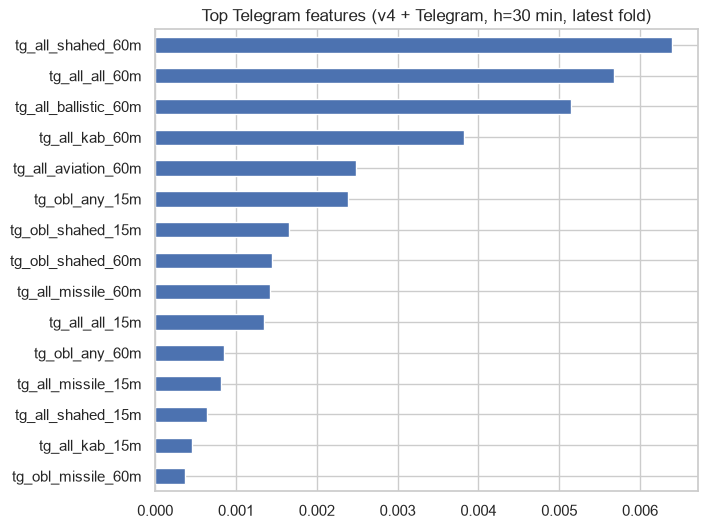

In [8]:
imp = pd.Series(last_model.feature_importance("gain"), index=last_model.feature_name()); imp /= imp.sum()
print("gain share of Telegram features:", round(imp[[c for c in imp.index if c.startswith("tg_")]].sum(), 3))
imp[[c for c in imp.index if c.startswith("tg_")]].sort_values().tail(15).plot.barh(figsize=(7, 6),
    title="Top Telegram features (v4 + Telegram, h=30 min, latest fold)"); plt.show()

## Conclusions (fill in after running)
- Coverage / lead time of posts: …
- v4 + Telegram vs v4: …
- Which threat types / oblast mentions matter: …